# Validation of the automated count of AF488⁺ cells against human counts

**Question.** Does the automated method count as many AF488⁺ cells per section as a human does, and does it lead to the same conclusion about WT3 and GD1 assembloids?

**One measure.** The total number of AF488⁺ cells counted in a section, by a human and by the automated method, in the same area of the same section. Cell-by-cell matching (precision, recall) is not used here: the paper reports counts per section, so the count per section is what has to agree.

**Human counts.** Two human annotators placed one dot on every AF488⁺ cell they saw, on the AF488 image, without seeing the automated result.

| | sections | area counted | dots |
|---|---|---|---|
| **Human annotator 1** | 14 (WT3 7, GD1 7; 11 slides) | the whole section | 3,377 |
| **Human annotator 2** | 13 (WT3 8, GD1 5; 11 slides) | from 50 µm before the junction line to the far edge of the organoid where AF488 is not at home | 843 (730 in this area) |

**Automated count.** AF488⁺ cells are counted as **objects of an AF488 mask**. The AF488 image (brightest plane over z) is smoothed (Gaussian, σ 0.5 µm), its local background (Gaussian, σ 20 µm) is subtracted, and the result is thresholded inside the tissue at the median + 8 robust SD (1.4826 × MAD) of the section's own tissue pixels, so every section has its own threshold. (Until 9 November 2026 the threshold was the median + 5 robust SD; that version is compared in Table S1.) Objects smaller than 20 µm² are removed and holes smaller than 10 µm² filled. Each connected object counts as one cell. The masks were computed once for every section of the analysis run (614 sections) and are read here.

**Contents.** (1) Totals per section, human against automated: concordance and Bland–Altman agreement (Figure 1), with the same mask at 5 SD and two alternative methods for comparison (Table S1). (2) Whether the automated count gives the same WT3 against GD1 result as the human count, on the same sections, and the result on all 614 sections (Figure 2). (3) Twelve regions of 120 × 120 µm to compare the two counts by eye (Figure 3). (4) Conclusion and Methods.

In [1]:
import ssl

# Some Python installations on Windows cannot read the Windows certificate store.
try:
    ssl.create_default_context()
except ssl.SSLError:  # pragma: no cover - machine-specific
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import json
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().resolve()
while not (ROOT / "microscopy_viewer").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

# ---------------------------------------------------------------- Settings: change these
DATA = Path(r"D:\Slidescanner extracted")
RUN = DATA / "cells_analysis" / "2026-10-28_090440 re-scored"      # the cells-analysis run (614 sections)
OUT = DATA / "run_analysis_20261028"                                # caches written by notebooks/dataset
MASKS = OUT / "af488_mask"                                          # af488_masks.py: the AF488 mask, every section
FIGURES = OUT / "figures_official"
DESIGN_CSV = DATA / "Image_File_List.csv"
GENOTYPES = ["WT3", "GD1"]       # WT2 is in the file list but not part of this study
CHANNEL = "AF488"
METHOD_MASK = "kmad8"            # the counting method: AF488 mask objects, Gaussian 20 µm background, median + 8 SD
EARLIER_MASK = "kmad5"           # the counting method until 9 Nov 2026 (median + 5 SD), for comparison in Table S1
GAP_UM, NEAR_UM = 2.0, 300.0     # the earlier definition of crossed (beside the line, 2–300 µm past it), to compare
# crossed now = anywhere on the far side of the junction line (sides.py: the line extended past its ends)
SEED, N_BOOT = 0, 2000
SAVE_FIGURES = True
# ----------------------------------------------------------------------------------------

FIGURES.mkdir(parents=True, exist_ok=True)

# Publication style: black and greys only for data; images in the stain's own colour.
INK, DARK, MID, LIGHT = "#000000", "#4d4d4d", "#8c8c8c", "#d9d9d9"
GENOTYPE_FACE = {"WT3": DARK, "GD1": "#ffffff"}        # filled vs open, black edge on both
GENOTYPE_MARKER = {"WT3": "o", "GD1": "s"}
mpl.rcParams.update({
    "font.family": "Arial", "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "normal",
    "axes.labelsize": 9, "axes.linewidth": 1.0, "axes.edgecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.width": 1.0, "ytick.major.width": 1.0, "xtick.major.size": 4, "ytick.major.size": 4,
    "xtick.color": INK, "ytick.color": INK, "axes.prop_cycle": mpl.cycler(color=[INK, MID, DARK, LIGHT]),
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 120,
    "savefig.dpi": 600, "savefig.bbox": "tight", "svg.fonttype": "none", "pdf.fonttype": 42,
})


def save(fig, name):
    """Write the figure as vector (svg, pdf) and 600 dpi png into FIGURES."""
    if SAVE_FIGURES:
        for ext in ("svg", "pdf", "png"):
            fig.savefig(FIGURES / f"{name}.{ext}")


def panel_letters(axes, x=-0.22, y=1.04):
    for letter, ax in zip("abcdefghijklmnop", np.ravel(axes)):
        ax.text(x, y, letter, transform=ax.transAxes, fontsize=12, fontweight="bold", va="bottom")


def p_text(p):
    return "n.s." if not np.isfinite(p) or p >= 0.05 else ("P < 0.001" if p < 0.001 else f"P = {p:.3f}")


design = pd.read_csv(DESIGN_CSV)
design["name"] = design["File_Name"].str.replace(".ome.tiff", "", regex=False)
design = design[design["Genotype"].isin(GENOTYPES)].copy()
design["slide"] = design["Genotype"] + " e" + design["Experiment"].astype(str) + " s" + design["Slide"].astype(str)
design["Experiment"] = design["Experiment"].astype(str)

In [2]:
import logging

import statsmodels.formula.api as smf
from IPython.display import display
from scipy import ndimage
from scipy.spatial import cKDTree
from skimage.measure import label, regionprops_table
from skimage.morphology import remove_small_holes, remove_small_objects
from skimage.segmentation import find_boundaries

sys.path.insert(0, str(ROOT / "notebooks" / "validation"))
import classical_vs_cellpose as cv  # noqa: E402  (the AF488 mask's helpers)
sys.path.insert(0, str(ROOT / "notebooks" / "dataset"))
import section_outline  # noqa: E402  (objects outside the section are not counted)

from microscopy_viewer import junction_analysis as ja  # noqa: E402
from microscopy_viewer import loaders  # noqa: E402

sys.path.insert(0, str(ROOT / "notebooks" / "official_analysis"))
import sides  # noqa: E402  (which side of the junction line a point is on: the line extended past its ends)

logging.getLogger("tifffile").setLevel(logging.ERROR)   # OME headers with odd characters: harmless

# ---------------------------------------------------------------- Settings for this notebook
CACHE = OUT / "cache"                       # the run's cells near the line (dataset/03, 04)
ANNOTATORS = {                              # folder of each human annotator's dots (james_clicks.py)
    "human annotator 1": OUT / "james_counts",
    "human annotator 2": OUT / "quillan_counts",
}
AREA_2_UM = -50.0                           # annotator 2 counted from 50 µm before the line to the far edge of the other organoid
RETRAINED = "Cellpose AF488 · retrained (cross-validated)"
ROI_UM, ROI_MARGIN_UM = 120.0, 60.0         # side of a gallery region; margin read round it for the mask
ROI_SEED = 3                                # the draw of gallery regions
DISPLAY_PCT = (0.5, 99.8)                   # each region's AF488 display range, percentiles of its own pixels
NUCLEAR_STEP = 8                            # the tissue mask is made at 1/8 (as classical_vs_cellpose)
# ----------------------------------------------------------------------------------------
GREEN = mpl.colors.LinearSegmentedColormap.from_list("green_on_black", ["#000000", "#00ff00"])
MAGENTA = "#ff00ff"
ANNOTATOR_MARKER = {"human annotator 1": "o", "human annotator 2": "s"}


def section_info(name):
    """The run's record of one section (file, pixel size, junction length …)."""
    return json.loads((RUN / "cells" / f"{name}.json").read_text(encoding="utf-8"))


def junction_line(name):
    line = section_info(name)["line"]
    return np.asarray(json.loads(line) if isinstance(line, str) else line, float)     # (y, x) in µm


def mask_objects(name, mask=METHOD_MASK):
    """The counting method's objects of one section (AF488 mask, median + 8 robust SD of the section's own tissue)."""
    o = pd.read_parquet(MASKS / name / "objects.parquet")
    o = o[o["mask"] == mask].rename(columns={
        "Centroid Y (µm)": "y", "Centroid X (µm)": "x", "Distance to the junction line (µm)": "d",
        "Beside the junction line": "beside", "In region": "region"})
    return o.reset_index(drop=True)


def home_sign(name):
    """+1 or −1 so that `away` = side × sign is + past the line, in the organoid where AF488 is not at home.
    AF488's home is the side of the extended junction line holding more AF488 mask-object area (sides.py)."""
    o = mask_objects(name)
    return sides.home_sign(sides.raw_side(o[["y", "x"]].to_numpy(float), junction_line(name)), o["Area (µm²)"])


def away_of(frame, name, sign):
    """Distance past the junction line (µm) of any rows with y, x (µm): > 0 crossed, < 0 at home (sides.py)."""
    return sides.away(frame[["y", "x"]].to_numpy(float), junction_line(name), sign)


# The human-counted sections: who counted them, genotype, slide, junction length, home sign.
dots = []
for annotator, folder in ANNOTATORS.items():
    dots.append(pd.read_parquet(folder / "clicks.parquet").assign(annotator=annotator))
dots = pd.concat(dots, ignore_index=True)
counted = (dots.groupby(["annotator", "name"]).size().rename("dots").reset_index()
           .merge(design[["name", "Genotype", "Experiment", "slide"]], on="name", how="left"))
counted["length (mm)"] = [section_info(n)["junction_length_um"] / 1000 for n in counted["name"]]
counted["sign"] = [home_sign(n) for n in counted["name"]]
signs = counted.drop_duplicates("name").set_index("name")["sign"]
dots["away"] = np.nan
for name, part in dots.groupby("name"):
    dots.loc[part.index, "away"] = away_of(part, name, signs[name])
print(counted.groupby(["annotator", "Genotype"]).agg(sections=("name", "size"), slides=("slide", "nunique"),
                                                     dots=("dots", "sum")).loc[list(ANNOTATORS)])

                            sections  slides  dots
annotator         Genotype                        
human annotator 1 GD1              7       5  1249
                  WT3              7       6  2128
human annotator 2 GD1              5       5   270
                  WT3              8       6   573


## 1. Totals per section, human and automated, in the same area

Each section's human count is the number of dots in the area the annotator counted. The automated count is the number of mask objects whose centroid lies in that same area:

- **Annotator 1** (whole section): all mask objects of the section. The mask is confined to the tissue.
- **Annotator 2** (near the junction): the objects with *away* ≥ −50 µm, i.e. the whole of the other organoid and 50 µm of the home side. *away* is the signed distance to the junction line, extended straight past both its ends so that every point has a side (`sides.py`), with + pointing into the organoid where AF488 is not at home. AF488's home is the side of the line holding more AF488 mask-object area (the 8 SD mask's; the 5 SD mask gives the same side in all 614 sections). The dots, and the cells and objects of the other methods, are placed against the same line in the same way. 113 of annotator 2's 843 dots lie outside this area (more than 50 µm before the line). They are not used, and neither are the objects there.

The table also lists the methods compared in Table S1, counted in the same area: the **same mask at median + 5 robust SD** (the counting method until 9 November 2026), the **per-nucleus rule** (the earlier rule: a Cellpose nucleus is AF488⁺ when its median-filtered AF488 mean exceeds the junction region's median + 7 robust SD) and **Cellpose on AF488, fine-tuned** on human dots (cross-validated: each section was counted by a model that had not seen its dots).

In [3]:
def in_counted_area(frame, annotator, name, sign):
    """Which rows (dots, objects or cells; y, x in µm) lie in the area the annotator counted.
    Annotator 1 counted the whole section; annotator 2 from 50 µm before the line to the far edge of the other organoid."""
    if annotator == "human annotator 1":
        return np.ones(len(frame), bool)
    return away_of(frame, name, sign) >= AREA_2_UM


rows = []
for _, s in counted.iterrows():
    name, folder = s["name"], ANNOTATORS[s["annotator"]]
    d = dots[(dots["annotator"] == s["annotator"]) & (dots["name"] == s["name"])]
    objects = mask_objects(s["name"])
    cells = pd.read_parquet(folder / "cells" / f"{name}.parquet", columns=["y", "x", f"{CHANNEL} positive"])
    retrained = pd.read_parquet(folder / "methods" / "objects" / "cellpose488_retrained" / f"{name}.parquet")
    retrained = retrained[retrained["method"] == RETRAINED]
    rows.append({
        "annotator": s["annotator"], "name": s["name"], "Genotype": s["Genotype"], "slide": s["slide"],
        "length (mm)": s["length (mm)"], "human": int(in_counted_area(d, s["annotator"], name, s["sign"]).sum()),
        "automated": int(in_counted_area(objects, s["annotator"], name, s["sign"]).sum()),
        "mask 5 SD": int(in_counted_area(mask_objects(name, EARLIER_MASK), s["annotator"], name, s["sign"]).sum()),
        "per-nucleus rule": int((in_counted_area(cells, s["annotator"], name, s["sign"])
                                 & cells[f"{CHANNEL} positive"].to_numpy(bool)).sum()),
        "retrained Cellpose": int(in_counted_area(retrained, s["annotator"], name, s["sign"]).sum()),
    })
totals = pd.DataFrame(rows)
totals["section"] = [f"{a[-1]}-{i + 1:02d}" for a, i in zip(totals["annotator"],
                                                          totals.groupby("annotator").cumcount())]
display(totals.drop(columns=["name"]).set_index(["annotator", "section"]))
print("dots outside the counted area, annotator 2:",
      int(counted.loc[counted["annotator"] == "human annotator 2", "dots"].sum()
          - totals.loc[totals["annotator"] == "human annotator 2", "human"].sum()))

Genotype       slide  length (mm)  human  automated  mask 5 SD  per-nucleus rule  retrained Cellpose
annotator         section                                                                                                     
human annotator 1 1-01         WT3   WT3 e8 s2     1.375014    511        282        626               610                 260
                  1-02         WT3   WT3 e8 s3     1.440674    347        208        438               517                 242
                  1-03         WT3   WT3 e9 s6     0.737287    375        414        541              1871                 213
                  1-04         WT3  WT3 e10 s2     0.865459    275        147        242               506                 134
                  1-05         WT3  WT3 e10 s2     0.540871    235        123        168               476                  90
                  1-06         WT3  WT3 e10 s4     1.372783    228        206        342               453                 183
                  1-07         WT3  WT3 e10 s7     0.450198    157         72        141               138                  75
                  1-08         GD1   GD1 e8 s1     0.554851     90         36         78               135                  50
                  1-09         GD1   GD1 e8 s1     0.483992    232         84        134               144                  84
                  1-10         GD1   GD1 e8 s2     0.977538    333        231        413               930                 209
                  1-11         GD1   GD1 e9 s7     0.584104    112         39         72                69                  44
                  1-12         GD1  GD1 e10 s1     1.067840     98         35         77               129                  33
                  1-13         GD1  GD1 e10 s6     1.062361    172         70        122               157                  80
                  1-14         GD1  GD1 e10 s6     0.995870    212        163        290               415                 158
human annotator 2 2-01         WT3   WT3 e8 s3     1.288475     54         31         84                76                  20
                  2-02         WT3   WT3 e9 s4     0.948306     75        120        207               266                  32
                  2-03         WT3   WT3 e9 s4     1.139706     90        167        373               333                  57
                  2-04         WT3   WT3 e9 s6     0.709257     21         19         46               109                   9
                  2-05         WT3  WT3 e10 s1     0.856097     40          5         18                14                   5
                  2-06         WT3  WT3 e10 s3     1.583823     99         70        103               203                  69
                  2-07         WT3  WT3 e10 s4     1.330960     77         37         65               110                  33
                  2-08         WT3  WT3 e10 s4     1.553808     67         39         72                85                  33
                  2-09         GD1   GD1 e8 s2     0.962723     52         11         34                55                  27
                  2-10         GD1   GD1 e9 s1     1.373686     41          5         13                11                   6
                  2-11         GD1   GD1 e9 s4     1.450042     44         18         66                53                  18
                  2-12         GD1  GD1 e10 s1     1.177393     46          8         36                21                  21
                  2-13         GD1  GD1 e10 s3     1.188435     24          4         38                 8                   5

dots outside the counted area, annotator 2: 113


### Agreement

- **Lin's concordance correlation coefficient (CCC)** on log₁₀ counts. It is 1 only when every section lies on the identity line, so it measures agreement rather than correlation. Log counts are used because the counts span more than a factor of ten (about 20 to 500 cells); on raw counts the largest sections would dominate. The CCC on raw counts is given as well.
- **Bland–Altman analysis on the ratio scale.** For each section, log₂(automated ÷ human). Bias is the mean of this ratio and the 95 % limits of agreement (LoA) are bias ± 1.96 SD. Both are shown back-transformed as ratios (×).
- **Spearman ρ** (rank agreement).
- **95 % CIs** come from 2,000 bootstrap resamples of sections. In the pooled analysis sections are resampled within each annotator.

In [4]:
def lin_ccc(x, y):
    """Lin's concordance correlation coefficient: 1 only when every point lies on the identity line."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    sxy = np.mean((x - x.mean()) * (y - y.mean()))
    return 2 * sxy / (x.var() + y.var() + (x.mean() - y.mean()) ** 2)


def agreement_numbers(frame, method):
    """CCC (on log10 counts and on counts), Bland–Altman on log2(method ÷ human), Spearman ρ."""
    h, m = frame["human"].to_numpy(float), frame[method].to_numpy(float)
    log_ratio = np.log2(np.maximum(m, 0.5) / np.maximum(h, 0.5))     # a zero count is taken as 0.5
    bias, sd = log_ratio.mean(), log_ratio.std(ddof=1)
    return {"CCC (log counts)": lin_ccc(np.log10(h), np.log10(np.maximum(m, 0.5))), "CCC (counts)": lin_ccc(h, m),
            "bias": bias, "LoA low": bias - 1.96 * sd, "LoA high": bias + 1.96 * sd,
            "Spearman ρ": stats.spearmanr(h, m).correlation}


def with_ci(frame, method, seed=SEED):
    """The numbers and their 95 % CIs, sections resampled with replacement (within annotator when pooled)."""
    rng = np.random.default_rng(seed)
    point = agreement_numbers(frame, method)
    groups = [g.index.to_numpy() for _, g in frame.groupby("annotator")]
    draws = []
    for _ in range(N_BOOT):
        pick = np.concatenate([rng.choice(g, len(g)) for g in groups])
        draws.append(agreement_numbers(frame.loc[pick], method))
    draws = pd.DataFrame(draws)
    return {k: (v, *np.nanpercentile(draws[k], [2.5, 97.5])) for k, v in point.items()} | {"n": len(frame)}


SETS = {"pooled": totals, **{a: totals[totals["annotator"] == a] for a in ANNOTATORS}}
agree = {(method, set_name): with_ci(frame, method)
         for method in ("automated", "mask 5 SD", "per-nucleus rule", "retrained Cellpose")
         for set_name, frame in SETS.items()}


def fmt(v, ratio=False, digits=2):
    """'est (lo–hi)', a log2 ratio shown as a fold (×)."""
    est, lo, hi = (2 ** np.asarray(v) if ratio else np.asarray(v))
    return f"{est:.{digits}f} ({lo:.{digits}f}–{hi:.{digits}f})"


def agreement_table(method):
    rows = {}
    for set_name in SETS:
        a = agree[method, set_name]
        rows[set_name] = {"n sections": a["n"], "Lin's CCC (log counts)": fmt(a["CCC (log counts)"]),
                          "Lin's CCC (counts)": fmt(a["CCC (counts)"]),
                          "bias (automated ÷ human)": fmt(a["bias"], ratio=True),
                          "95 % LoA, lower": fmt(a["LoA low"], ratio=True),
                          "95 % LoA, upper": fmt(a["LoA high"], ratio=True),
                          "Spearman ρ": fmt(a["Spearman ρ"])}
    return pd.DataFrame(rows).T


print("Counting method (AF488 mask objects) against the human totals; 95 % CI from", N_BOOT, "section bootstraps")
display(agreement_table("automated"))

Counting method (AF488 mask objects) against the human totals; 95 % CI from 2000 section bootstraps


,n sections,Lin's CCC (log counts),Lin's CCC (counts),bias (automated ÷ human),"95 % LoA, lower","95 % LoA, upper",Spearman ρ
pooled,27,0.66 (0.55–0.75),0.76 (0.61–0.86),0.48 (0.37–0.61),0.12 (0.09–0.19),1.83 (1.20–2.56),0.90 (0.76–0.97)
human annotator 1,14,0.59 (0.40–0.69),0.63 (0.42–0.77),0.54 (0.45–0.65),0.26 (0.23–0.34),1.09 (0.72–1.45),0.92 (0.71–0.99)
human annotator 2,13,0.34 (0.15–0.51),0.54 (0.27–0.62),0.42 (0.26–0.67),0.07 (0.04–0.15),2.54 (1.07–4.46),0.83 (0.47–0.99)


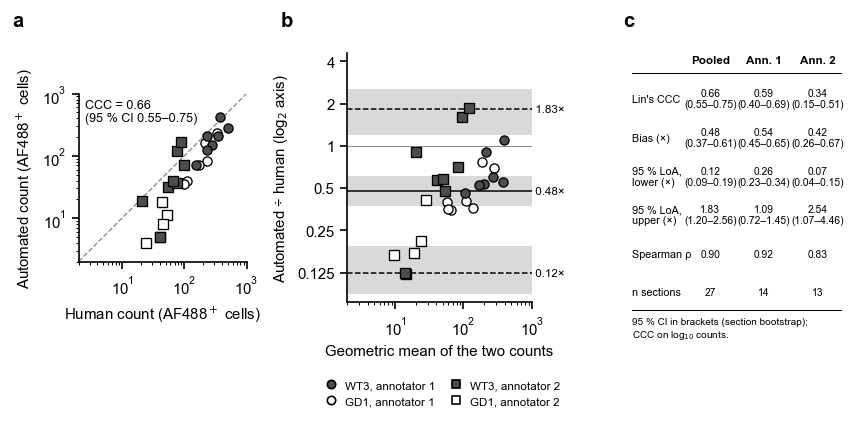

In [5]:
def section_markers(ax, frame, x, y):
    """One marker per section: WT3 filled, GD1 open; annotator 1 circles, annotator 2 squares."""
    for (annotator, genotype), part in frame.groupby(["annotator", "Genotype"]):
        ax.scatter(x(part), y(part), s=30, marker=ANNOTATOR_MARKER[annotator], facecolor=GENOTYPE_FACE[genotype],
                   edgecolor=INK, linewidth=0.8, zorder=3)


fig = plt.figure(figsize=(7.4, 2.7))
grid = fig.add_gridspec(1, 3, width_ratios=[1, 1.1, 0.8], wspace=0.62)
ax_a, ax_b, ax_c = (fig.add_subplot(grid[0, i]) for i in range(3))

# (a) automated against human, log–log, identity line
low, high = 2, 1000
ax_a.plot([low, high], [low, high], color=MID, lw=0.8, ls="--", zorder=1)
section_markers(ax_a, totals, lambda p: p["human"], lambda p: p["automated"])
ax_a.set(xscale="log", yscale="log", xlim=(low, high), ylim=(low, high), aspect="equal",
         xlabel="Human count (AF488$^+$ cells)", ylabel="Automated count (AF488$^+$ cells)")
a = agree["automated", "pooled"]
ax_a.text(0.04, 0.97, f"CCC = {a['CCC (log counts)'][0]:.2f}\n(95 % CI {a['CCC (log counts)'][1]:.2f}–"
          f"{a['CCC (log counts)'][2]:.2f})", transform=ax_a.transAxes, va="top", fontsize=7.5)

# (b) Bland–Altman on the ratio scale, with the CIs of the bias and limits as grey bands
geo_mean = lambda p: np.sqrt(p["human"] * p["automated"])
log_ratio = lambda p: np.log2(p["automated"] / p["human"])
for key, style in (("bias", "-"), ("LoA low", "--"), ("LoA high", "--")):
    est, lo, hi = a[key]
    ax_b.axhspan(lo, hi, color=LIGHT, lw=0, zorder=0)
    ax_b.axhline(est, color=INK, lw=0.9, ls=style, zorder=1)
    ax_b.text(1.0, est, f" {2 ** est:.2f}×", transform=ax_b.get_yaxis_transform(), va="center", fontsize=7)
ax_b.axhline(0, color=MID, lw=0.6, zorder=1)
section_markers(ax_b, totals, geo_mean, log_ratio)
ticks = np.array([0.125, 0.25, 0.5, 1, 2, 4])
ax_b.set(xscale="log", xlim=(low, high), ylim=(-3.7, 2.2), yticks=np.log2(ticks),
         yticklabels=[f"{t:g}" for t in ticks], xlabel="Geometric mean of the two counts",
         ylabel="Automated ÷ human (log$_2$ axis)")

# legend for the markers, under panel b
handles = [mpl.lines.Line2D([], [], ls="", marker=ANNOTATOR_MARKER[an], mfc=GENOTYPE_FACE[g], mec=INK, ms=5,
                            label=f"{g}, {an.replace('human annotator', 'annotator')}")
           for an in ANNOTATORS for g in GENOTYPES]
ax_b.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.27), ncol=2, fontsize=7, handletextpad=0.2,
            columnspacing=0.8)

# (c) the numbers per annotator, as a compact table drawn as text: one column per set of sections
ax_c.axis("off")
COLUMN_X = {"pooled": 0.58, "human annotator 1": 0.98, "human annotator 2": 1.38}
HEAD = {"pooled": "Pooled", "human annotator 1": "Ann. 1", "human annotator 2": "Ann. 2"}


def ci_text(v, ratio=False):
    est, lo, hi = 2 ** np.asarray(v) if ratio else np.asarray(v)
    return f"{est:.2f}\n({lo:.2f}–{hi:.2f})"


ROWS = [("Lin's CCC", lambda s: ci_text(s["CCC (log counts)"])),
        ("Bias (×)", lambda s: ci_text(s["bias"], ratio=True)),
        ("95 % LoA,\nlower (×)", lambda s: ci_text(s["LoA low"], ratio=True)),
        ("95 % LoA,\nupper (×)", lambda s: ci_text(s["LoA high"], ratio=True)),
        ("Spearman ρ", lambda s: f"{s['Spearman ρ'][0]:.2f}"),
        ("n sections", lambda s: f"{s['n']}")]
y, step = 0.97, 0.155
for set_name, x in COLUMN_X.items():
    ax_c.text(x, y, HEAD[set_name], ha="center", va="center", fontsize=7, fontweight="bold", transform=ax_c.transAxes)
ax_c.plot([0, 1.55], [y - 0.05] * 2, color=INK, lw=0.6, transform=ax_c.transAxes, clip_on=False)
for row, value in ROWS:
    y -= step
    ax_c.text(0, y, row, ha="left", va="center", fontsize=6.5, transform=ax_c.transAxes, linespacing=1.1)
    for set_name, x in COLUMN_X.items():
        ax_c.text(x, y, value(agree["automated", set_name]), ha="center", va="center", fontsize=6.2,
                  transform=ax_c.transAxes, linespacing=1.1)
ax_c.plot([0, 1.55], [y - 0.07] * 2, color=INK, lw=0.6, transform=ax_c.transAxes, clip_on=False)
ax_c.text(0, y - 0.1, "95 % CI in brackets (section bootstrap);\nCCC on log$_{10}$ counts.", fontsize=6, va="top",
          transform=ax_c.transAxes)

fig.canvas.draw()                      # letters at one height (panel a is square, so shorter)
for letter, ax, dx in (("a", ax_a, -0.075), ("b", ax_b, -0.075), ("c", ax_c, -0.01)):
    fig.text(ax.get_position().x0 + dx, 0.95, letter, fontsize=12, fontweight="bold", va="bottom")
save(fig, "fig1_validation_counts")
plt.show()

**Figure 1 | Automated and human counts of AF488⁺ cells per section: concordance and agreement.** **a**, Automated against human count of AF488⁺ cells per section, in the area the human counted. Log–log axes, dashed identity line; Lin's CCC on log counts with its 95 % bootstrap CI (sections resampled). **b**, Bland–Altman plot on the ratio scale: automated ÷ human against the geometric mean of the two counts. Solid line, bias; dashed lines, 95 % limits of agreement; grey bands, their 95 % CIs. **c**, Agreement per annotator and pooled: CCC (log counts) and bias with 95 % CIs, limits of agreement, Spearman ρ, and n (sections). Markers: one per section; filled, WT3; open, GD1; circles, human annotator 1 (whole section, n = 14); squares, human annotator 2 (near the junction, n = 13).

**What it shows (9 November 2026; counting method at median + 8 robust SD).**

- **The automated method counts about half as many cells as the humans.** Pooled over the 27 sections the mean ratio automated ÷ human is **0.48× (95 % CI 0.37–0.61)**. With the earlier 5 SD threshold it was 1.05× (0.86–1.28), with no overall bias. The higher threshold leaves out background patches and fragments, but also many of the dim cells the humans dotted.
- **Concordance is lower than at 5 SD; ranking is as good.** Lin's CCC on log counts is **0.66 (0.55–0.75)** (0.76 on raw counts), against 0.83 at 5 SD: CCC is lowered by the systematic under-count. Spearman ρ is 0.90 (0.87 at 5 SD), so the sections are ranked as well as before.
- **Individual sections vary widely.** The 95 % limits of agreement run from **0.12× (0.09–0.19) to 1.83× (1.20–2.56)**: in a single section the automated count can be anything from an eighth of the human count to nearly twice it.
- **The under-count is larger in sections with few cells.** In panel b the ratio rises with the size of the count: the log ratio regressed on the log geometric mean has a slope of +0.42 (pooled, P < 0.001; +0.43 against annotator 1). At 5 SD the pooled slope was +0.18 (P = 0.14).
- **The two annotators.** Against annotator 1 (whole sections, 90–511 cells), CCC is 0.59 (0.40–0.69), bias 0.54× (0.45–0.65), LoA 0.26–1.09×, Spearman ρ 0.92 (at 5 SD: CCC 0.87, bias 0.96×). Against annotator 2 (the junction and the whole other organoid, 21–99 cells), agreement is poor: CCC 0.34 (0.15–0.51), bias 0.42× (0.26–0.67), LoA 0.07–2.54×, ρ 0.83. The two WT3 sections of one slide (2-02, 2-03) still have more objects than dots (1.6× and 1.9×; 2.8× and 4.2× at 5 SD), while in four of the five GD1 sections the mask finds about a fifth of the dots or fewer (2-09, 2-10, 2-12, 2-13: 4–11 objects against 24–52 dots).
- **The disagreement depends on genotype, more strongly than at 5 SD** (Figure 1b, filled against open markers; table in section 2). In WT3 sections the automated method finds 0.65× the human count (geometric mean), in GD1 sections 0.32×. The difference is now significant (Mann–Whitney on log ratios, P = 0.003, 15 against 12 sections; at 5 SD 1.26× against 0.84×, P = 0.057) and has the same sign for both annotators (0.64× against 0.45×, P = 0.073; and 0.67× against 0.20×, P = 0.019). The mask misses relatively twice as many GD1 cells as WT3 cells, so it enlarges the WT3 ÷ GD1 fold (section 2).


### Table S1. The mask objects at 8 SD against the earlier threshold and the alternatives

The same agreement for the same mask at the earlier threshold (median + 5 robust SD, the counting method until 9 November 2026) and for the two alternative methods, in the same areas of the same sections.


In [6]:
METHOD_LABELS = {"automated": "AF488 mask objects, 8 SD (the counting method)",
                 "mask 5 SD": "AF488 mask objects, 5 SD (the counting method until 9 Nov 2026)",
                 "per-nucleus rule": "Per-nucleus rule (median filter, median + 7 SD)",
                 "retrained Cellpose": "Cellpose on AF488, fine-tuned (cross-validated)"}
supplementary = pd.concat({METHOD_LABELS[m]: agreement_table(m) for m in METHOD_LABELS}, names=["method", "sections"])
supplementary.insert(1, "median count ÷ human",
                     [f"{np.median(SETS[s][m] / SETS[s]['human']):.2f}" for m in METHOD_LABELS for s in SETS])
supplementary.to_csv(FIGURES / "table_s1_methods_against_human.csv", encoding="utf-8-sig")
display(supplementary)

n sections median count ÷ human Lin's CCC (log counts) Lin's CCC (counts) bias (automated ÷ human)   95 % LoA, lower    95 % LoA, upper  \
method                                             sections                                                                                                                                                    
AF488 mask objects, 8 SD (the counting method)     pooled                    27                 0.52       0.66 (0.55–0.75)   0.76 (0.61–0.86)         0.48 (0.37–0.61)  0.12 (0.09–0.19)   1.83 (1.20–2.56)   
                                                   human annotator 1         14                 0.53       0.59 (0.40–0.69)   0.63 (0.42–0.77)         0.54 (0.45–0.65)  0.26 (0.23–0.34)   1.09 (0.72–1.45)   
                                                   human annotator 2         13                 0.48       0.34 (0.15–0.51)   0.54 (0.27–0.62)         0.42 (0.26–0.67)  0.07 (0.04–0.15)   2.54 (1.07–4.46)   
AF488 mask objects, 5 SD (the counting method u... pooled                    27                 1.04       0.84 (0.71–0.91)   0.84 (0.62–0.93)         1.05 (0.86–1.27)  0.36 (0.27–0.52)   3.07 (2.04–4.35)   
                                                   human annotator 1         14                 0.89       0.87 (0.72–0.93)   0.85 (0.69–0.91)         0.96 (0.82–1.13)  0.51 (0.44–0.68)   1.81 (1.38–2.11)   
                                                   human annotator 2         13                 1.07       0.50 (0.32–0.60)   0.26 (0.17–0.75)         1.15 (0.80–1.70)  0.28 (0.17–0.55)   4.72 (2.40–7.69)   
Per-nucleus rule (median filter, median + 7 SD)    pooled                    27                 1.41       0.74 (0.62–0.82)   0.39 (0.29–0.76)         1.31 (0.99–1.75)  0.28 (0.19–0.50)   6.07 (3.83–8.64)   
                                                   human annotator 1         14                 1.49       0.62 (0.41–0.78)   0.25 (0.14–0.70)         1.47 (1.11–1.95)  0.48 (0.33–0.83)   4.52 (2.59–7.12)   
                                                   human annotator 2         13                 1.27       0.44 (0.15–0.62)   0.27 (0.16–0.57)         1.15 (0.71–1.89)  0.17 (0.10–0.45)  7.71 (3.26–13.02)   
Cellpose on AF488, fine-tuned (cross-validated)    pooled                    27                 0.47       0.68 (0.58–0.77)   0.69 (0.59–0.76)         0.44 (0.38–0.50)  0.18 (0.13–0.31)   1.04 (0.77–1.27)   
                                                   human annotator 1         14                 0.50       0.54 (0.34–0.65)   0.51 (0.33–0.62)         0.51 (0.45–0.59)  0.30 (0.26–0.38)   0.87 (0.68–1.03)   
                                                   human annotator 2         13                 0.43       0.35 (0.17–0.52)   0.45 (0.20–0.60)         0.37 (0.28–0.48)  0.13 (0.08–0.31)   1.04 (0.71–1.28)   

                                                                            Spearman ρ  
method                                             sections                             
AF488 mask objects, 8 SD (the counting method)     pooled             0.90 (0.76–0.97)  
                                                   human annotator 1  0.92 (0.71–0.99)  
                                                   human annotator 2  0.83 (0.47–0.99)  
AF488 mask objects, 5 SD (the counting method u... pooled             0.87 (0.70–0.94)  
                                                   human annotator 1  0.89 (0.65–0.99)  
                                                   human annotator 2  0.72 (0.33–0.89)  
Per-nucleus rule (median filter, median + 7 SD)    pooled             0.89 (0.74–0.97)  
                                                   human annotator 1  0.93 (0.77–1.00)  
                                                   human annotator 2  0.76 (0.29–0.99)  
Cellpose on AF488, fine-tuned (cross-validated)    pooled             0.97 (0.93–0.99)  
                                                   human annotator 1  0.92 (0.71–1.00)  

**What it shows (9 November 2026).** The **per-nucleus rule** (the earlier method) over-counts by 1.31× (0.99–1.75). Its limits of agreement are 0.28–6.07×, and in one section it counts 1,871 cells where the human counted 375: it calls nuclei positive in brightly stained neighbourhoods. The **fine-tuned Cellpose** ranks sections best (ρ 0.97) and has narrow limits of agreement (0.18–1.04×), but finds less than half the cells (bias 0.44×, 0.38–0.50). The **AF488 mask objects at 5 SD** were the only method whose totals were unbiased on average (1.05×, 0.86–1.28), with the highest CCC (0.83; 0.87 against annotator 1). **At 8 SD the same mask behaves more like the fine-tuned Cellpose**: it finds about half the cells (bias 0.48×, 0.37–0.61; median section 0.52× the human count), ranks sections well (ρ 0.90), and its CCC is lower (0.66 pooled, 0.59 against annotator 1, below the per-nucleus rule's 0.62 there). The counting method was changed to 8 SD on 9 November 2026; judged by agreement with the human totals the change is not an improvement. Its larger, genotype-dependent under-count is carried forward into section 2.


## 2. Does the automated count give the same biological conclusion?

**Same sections, same area.** On the human-counted sections, WT3 and GD1 are compared twice, once by the human total and once by the automated total. Both totals are divided by the section's junction length (mm) so that sections of different size compare. Each annotator is analysed separately, because the two counted different areas. Reported: the fold WT3 ÷ GD1 (ratio of the means), the two-sided Mann–Whitney test on sections, and n. With 13 or 14 sections these comparisons have little power. The question is whether the human and automated counts point the same way and give the same answer, not whether either is significant.

**All sections.** The study's primary outcome uses the automated method on all 614 analysed sections: AF488⁺ objects that **crossed**, i.e. lying anywhere on the far side of the junction line (extended past its ends), in the organoid where AF488 is not at home, per mm of junction line. These are compared between genotypes with a linear mixed model on log(1 + y), with genotype and experiment as fixed effects and slide as a random effect (sections from one slide are not independent).

In [7]:
def genotype_test(frame, column):
    """Fold WT3 / GD1 (ratio of the means; of the medians as a check on outliers),
    two-sided Mann–Whitney P, n per genotype (sections)."""
    w, g = (frame.loc[frame["Genotype"] == k, column].to_numpy(float) for k in GENOTYPES)
    return {"fold WT3/GD1": w.mean() / g.mean(), "fold of medians": np.median(w) / np.median(g),
            "Mann–Whitney P": stats.mannwhitneyu(w, g).pvalue,
            "n WT3": len(w), "n GD1": len(g)}


for column in ("human", "automated"):
    totals[f"{column} per mm"] = totals[column] / totals["length (mm)"]
same_sections = pd.DataFrame({(annotator, count): genotype_test(totals[totals["annotator"] == annotator],
                                                               f"{count} per mm")
                              for annotator in ANNOTATORS for count in ("human", "automated")}).T
display(same_sections.astype(float).round(3))

# Does the automated ÷ human ratio differ between the genotypes? (A genotype-dependent bias would change the fold.)
totals["log2 ratio"] = np.log2(totals["automated"] / totals["human"])
ratio_rows = []
for set_name, frame in SETS.items():
    frame = totals.loc[frame.index]
    w, g = (frame.loc[frame["Genotype"] == k, "log2 ratio"].to_numpy() for k in GENOTYPES)
    ratio_rows.append({"sections": set_name, "automated ÷ human, WT3 (geometric mean)": 2 ** w.mean(),
                       "automated ÷ human, GD1 (geometric mean)": 2 ** g.mean(),
                       "Mann–Whitney P": stats.mannwhitneyu(w, g).pvalue, "n WT3": len(w), "n GD1": len(g)})
ratio_by_genotype = pd.DataFrame(ratio_rows).set_index("sections")
display(ratio_by_genotype.round(3))

# Proportional bias: the Bland–Altman slope, ln(automated ÷ human) regressed on the ln geometric mean of the two counts
# (as the figure builder), for the counting method and for the same mask at 5 SD.
for set_name, frame in SETS.items():
    frame = totals.loc[frame.index]
    h = frame["human"].to_numpy(float)
    for method in ("automated", "mask 5 SD"):
        m = np.maximum(frame[method].to_numpy(float), 0.5)
        fit = stats.linregress(np.log(np.sqrt(m * h)), np.log(m / h))
        print(f"{set_name}, {'8 SD (counting method)' if method == 'automated' else '5 SD'}: Bland–Altman slope "
              f"{fit.slope:+.2f} (95 % CI {fit.slope - 1.96 * fit.stderr:+.2f} to {fit.slope + 1.96 * fit.stderr:+.2f}), "
              f"P = {fit.pvalue:.2g}, n = {len(h)}")

fold WT3/GD1  fold of medians  Mann–Whitney P  n WT3  n GD1
human annotator 1 human             1.456            1.819           0.097    7.0    7.0
                  automated         2.013            2.544           0.165    7.0    7.0
human annotator 2 human             1.585            1.723           0.065    8.0    5.0
                  automated         7.088            4.017           0.011    8.0    5.0

,"automated ÷ human, WT3 (geometric mean)","automated ÷ human, GD1 (geometric mean)",Mann–Whitney P,n WT3,n GD1
sections,,,,,
pooled,0.651,0.321,0.003,15,12
human annotator 1,0.637,0.453,0.073,7,7
human annotator 2,0.665,0.198,0.019,8,5


pooled, 8 SD (counting method): Bland–Altman slope +0.43 (95 % CI +0.24 to +0.62), P = 0.00016, n = 27
pooled, 5 SD: Bland–Altman slope +0.18 (95 % CI -0.05 to +0.40), P = 0.13, n = 27
human annotator 1, 8 SD (counting method): Bland–Altman slope +0.44 (95 % CI +0.24 to +0.63), P = 0.00083, n = 14
human annotator 1, 5 SD: Bland–Altman slope +0.37 (95 % CI +0.17 to +0.58), P = 0.0035, n = 14
human annotator 2, 8 SD (counting method): Bland–Altman slope +0.99 (95 % CI +0.64 to +1.33), P = 0.00017, n = 13
human annotator 2, 5 SD: Bland–Altman slope +0.77 (95 % CI +0.27 to +1.27), P = 0.012, n = 13


In [8]:
# The whole run: AF488 mask objects that crossed (anywhere on the far side of the extended line), per mm of junction line.
run_rows = []
for path in sorted((RUN / "cells").glob("*.json")):
    name = path.stem
    info = json.loads(path.read_text(encoding="utf-8"))
    o = mask_objects(name)
    raw = sides.raw_side(o[["y", "x"]].to_numpy(float), junction_line(name))
    crossed = raw * sides.home_sign(raw, o["Area (µm²)"]) > 0           # home: the side with more AF488 mask area
    run_rows.append({"name": name, "crossed": int(crossed.sum()), "length (mm)": info["junction_length_um"] / 1000})
run = pd.DataFrame(run_rows).merge(design[["name", "Genotype", "Experiment", "slide"]], on="name")
run["crossed per mm"] = run["crossed"] / run["length (mm)"]
TERM = "C(Genotype, Treatment('GD1'))[T.WT3]"


def mixed_fold(frame, column):
    """Fold WT3 / GD1 from a linear mixed model on log(1 + y): experiment fixed, slide random (REML)."""
    d = frame[["Genotype", "Experiment", "slide"]].assign(y=np.log1p(frame[column].to_numpy(float)))
    fit = smf.mixedlm("y ~ C(Genotype, Treatment('GD1')) + C(Experiment)", d, groups=d["slide"]).fit(reml=True)
    lo, hi = fit.conf_int().loc[TERM]
    return {"fold WT3/GD1": np.exp(fit.params[TERM]), "CI low": np.exp(lo), "CI high": np.exp(hi),
            "P": fit.pvalues[TERM], "sections": len(d), "slides": d["slide"].nunique()}


primary = mixed_fold(run, "crossed per mm")
print(f"{len(run)} sections ({', '.join(f'{g} {int((run.Genotype == g).sum())}' for g in GENOTYPES)}), "
      f"{run['slide'].nunique()} slides")
print(f"crossed AF488+ objects per mm: fold WT3/GD1 {primary['fold WT3/GD1']:.2f} "
      f"(95 % CI {primary['CI low']:.2f}–{primary['CI high']:.2f}), {p_text(primary['P'])} (P = {primary['P']:.2g})")
display(run.groupby("Genotype")["crossed per mm"].agg(["count", "mean", "median"]).loc[GENOTYPES].round(2))

614 sections (WT3 265, GD1 349), 36 slides
crossed AF488+ objects per mm: fold WT3/GD1 3.05 (95 % CI 1.96–4.76), P < 0.001 (P = 8.7e-07)


,count,mean,median
Genotype,,,
WT3,265,28.61,14.70
GD1,349,6.87,4.77


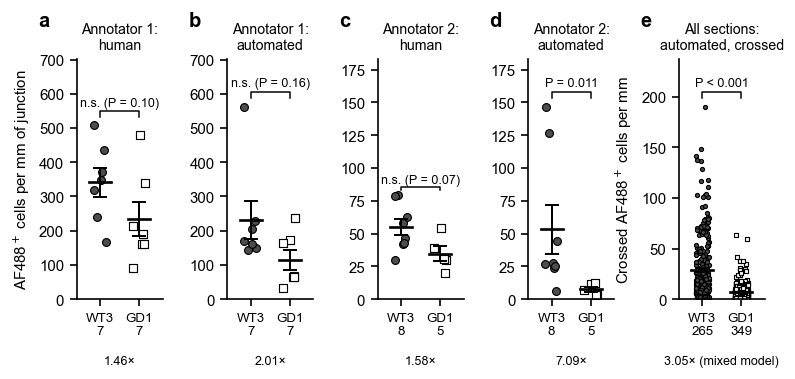

In [9]:
def dot_plot(ax, frame, column, p, seed=SEED, size=22):
    """Every section as a marker (WT3 filled circles, GD1 open squares), mean ± SEM in black, P above."""
    rng = np.random.default_rng(seed)
    top = 0.0
    for k, g in enumerate(GENOTYPES):
        y = frame.loc[frame["Genotype"] == g, column].to_numpy(float)
        top = max(top, y.max())
        ax.scatter(k + rng.uniform(-0.17, 0.17, len(y)), y, s=size, marker=GENOTYPE_MARKER[g],
                   facecolor=GENOTYPE_FACE[g], edgecolor=INK, linewidth=0.7, zorder=2)
        mean, sem = y.mean(), y.std(ddof=1) / np.sqrt(len(y))
        ax.errorbar(k, mean, yerr=sem, color=INK, capsize=4, lw=1.2, capthick=1.2, zorder=3)
        ax.plot([k - 0.28, k + 0.28], [mean, mean], color=INK, lw=1.6, zorder=3)
    counts = [int((frame["Genotype"] == g).sum()) for g in GENOTYPES]
    ax.set_xticks(range(2), [f"{g}\n{n}" for g, n in zip(GENOTYPES, counts)], fontsize=8)   # n = sections
    ax.set_xlim(-0.6, 1.6)
    y0 = top * 1.08
    ax.plot([0, 0, 1, 1], [y0 * 0.97, y0, y0, y0 * 0.97], color=INK, lw=0.9)
    ax.text(0.5, y0 * 1.01, p_text(p) if p < 0.05 else f"n.s. (P = {p:.2f})", ha="center", va="bottom", fontsize=7.5)
    ax.set_ylim(0, top * 1.25)


fig, axes = plt.subplots(1, 5, figsize=(7.4, 2.6), gridspec_kw={"wspace": 0.75})
for i, annotator in enumerate(ANNOTATORS):
    frame = totals[totals["annotator"] == annotator]
    for j, count in enumerate(("human", "automated")):
        ax = axes[2 * i + j]
        t = same_sections.loc[(annotator, count)]
        dot_plot(ax, frame, f"{count} per mm", t["Mann–Whitney P"])
        ax.set_title(f"{annotator.replace('human annotator', 'Annotator')}:\n{count}", fontsize=8.5)
        ax.text(0.5, -0.27, f"{t['fold WT3/GD1']:.2f}×", transform=ax.transAxes, ha="center", fontsize=7.5)
axes[0].set_ylabel("AF488$^+$ cells per mm of junction")
dot_plot(axes[4], run, "crossed per mm", primary["P"], size=6)
axes[4].set_title("All sections:\nautomated, crossed", fontsize=8.5)
axes[4].set_ylabel("Crossed AF488$^+$ cells per mm")
axes[4].text(0.5, -0.27, f"{primary['fold WT3/GD1']:.2f}× (mixed model)", transform=axes[4].transAxes,
             ha="center", fontsize=7.5)
# a common y range for the two counts of each annotator, so human and automated read alike
for i in range(2):
    top = max(axes[2 * i].get_ylim()[1], axes[2 * i + 1].get_ylim()[1])
    axes[2 * i].set_ylim(0, top)
    axes[2 * i + 1].set_ylim(0, top)
panel_letters(axes, x=-0.45, y=1.12)
save(fig, "fig2_same_conclusion")
plt.show()

**Figure 2 | The automated count gives the same direction of the WT3–GD1 difference as the human count, with a larger fold.** **a–d**, AF488⁺ cells per mm of junction line in the human-counted sections, counted by the human (**a**, **c**) and by the automated method in the same area (**b**, **d**). **a**, **b**, human annotator 1 (whole section); **c**, **d**, human annotator 2 (from 50 µm before the line to the far edge of the other organoid). Fold WT3 ÷ GD1 (ratio of means) under each panel; two-sided Mann–Whitney test on sections. **e**, Crossed AF488⁺ cells per mm of junction line (automated: mask objects anywhere on the far side of the line) in all 614 sections analysed. Fold WT3 ÷ GD1 and P from a linear mixed model on log(1 + y) (genotype and experiment fixed, slide random). One marker per section (WT3 filled circles, GD1 open squares); black lines, mean ± SEM.

**What it shows (9 November 2026; counting method at 8 SD).**

- **Same direction everywhere.** In every comparison WT3 has more AF488⁺ cells per mm of junction than GD1: with the human count, 1.46× (annotator 1, whole section) and 1.58× (annotator 2, the junction and the other organoid); with the automated count on the same sections and areas, 2.02× and 6.95× (2.54× and 3.66× as ratios of medians).
- **The automated fold is larger, more so than at 5 SD.** This follows from the genotype-dependent bias in section 1 (automated ÷ human 0.65× in WT3 against 0.32× in GD1). On the same sections the automated fold is 1.39 times the human fold for annotator 1 (1.26 times at 5 SD) and 4.4 times for annotator 2 (2.2 times at 5 SD). In annotator 2's GD1 sections the mask finds only 4–18 objects against 24–52 dots, while two WT3 sections of one slide keep more objects than dots; as ratios of medians the two folds are 3.66× against 1.72×.
- **Significance differs, but power is low.** With the automated count the annotator 2 comparison reaches P = 0.011 and the annotator 1 comparison does not (P = 0.13; it was P = 0.038 at 5 SD). With the human count neither does (P = 0.097 and 0.065). With 7 + 7 and 8 + 5 sections these comparisons have little power, so their P values are not evidence of no difference.
- **All sections.** On the 614 analysed sections (265 WT3, 349 GD1; 36 slides), WT3 sections have a mean of 28.6 crossed AF488⁺ objects per mm against 6.9 in GD1 (medians 14.7 and 4.8): **3.05× higher in WT3 (95 % CI 1.96–4.76; mixed model, P < 0.001)**, against 2.28× (1.42–3.67) with the 5 SD threshold.

**Same conclusion?** In direction, yes: the human counts and the automated counts both find more AF488⁺ cells in WT3 than in GD1. In size, no: on the sections where both exist the automated method enlarges the WT3 ÷ GD1 fold, by about 1.4× against the whole-section counts and more against the counts near the junction, because at 8 SD it misses relatively more GD1 cells than WT3 cells. The 3.05× of the full data set is therefore an upper estimate, further from the human folds (1.46–1.58×) than the 2.28× of the 5 SD threshold. The direction of the effect does not depend on the method; its size does.


## 3. Regions to compare by eye

Agreement in totals could hide errors that cancel out, for example missed dim cells balanced by split bright ones. Twelve regions of 120 × 120 µm show both counts on the image.

**How the regions were chosen.** Every human-counted section was divided into 120 µm squares on a fixed grid. A square qualifies when its centre lies in the tissue (and, for annotator 2, in the counted area) and it holds at least one dot or object. Eight squares were drawn at random (seed 3), each from a different section where possible, one per stratum: for each genotype, annotator 1 *dense* (top 20 % of human + automated count) and *sparse* (1–4 dots), and annotator 2 *at the line* (centre −20 to 40 µm from it) and *past the line* (centre 120–240 µm past it). Four more were not drawn at random: the two squares with the largest excess of human over automated count and the two with the largest excess of automated over human, each from a different section.

**How they are drawn.** AF488 (brightest plane over z) in green on black. Each region's display range runs from its own 0.5th to its 99.8th percentile (listed under the figure), so dim regions are stretched and brightness does not compare between regions. White outlines show the automated objects, recomputed on the crop plus a 60 µm margin with the section's stored threshold and checked against the stored objects. Grey outlines show objects outside the counted area, which are not counted. Magenta circles are the human dots. The grey dashed line is the junction line. Scale bar, 20 µm. Under each region: human count / automated count in the square.

In [10]:
def tiles_of(s):
    """Every ROI_UM square of a section (on a fixed grid) with the human and automated counts in it."""
    name, annotator = s["name"], s["annotator"]
    cells = pd.read_parquet(ANNOTATORS[annotator] / "cells" / f"{name}.parquet", columns=["y", "x"])
    objects = mask_objects(name)
    objects = objects[in_counted_area(objects, annotator, name, s["sign"])]
    d = dots[(dots["annotator"] == annotator) & (dots["name"] == name)]
    d = d[in_counted_area(d, annotator, name, s["sign"])]
    y0, x0 = np.floor(cells[["y", "x"]].min().to_numpy() / ROI_UM) * ROI_UM
    y1, x1 = cells[["y", "x"]].max().to_numpy()
    cy, cx = np.meshgrid(np.arange(y0, y1, ROI_UM) + ROI_UM / 2, np.arange(x0, x1, ROI_UM) + ROI_UM / 2,
                         indexing="ij")
    t = pd.DataFrame({"cy": cy.ravel(), "cx": cx.ravel()})
    gap, _ = cKDTree(cells[["y", "x"]].to_numpy()).query(t[["cy", "cx"]].to_numpy())
    t = t[gap <= 15].copy()                                  # the centre lies in the tissue
    t["away"] = away_of(t.rename(columns={"cy": "y", "cx": "x"}), name, s["sign"])
    if annotator == "human annotator 2":                     # the centre lies in the counted area
        t = t[t["away"] >= AREA_2_UM].copy()

    def count(points):
        iy = np.floor((points["y"].to_numpy() - y0) / ROI_UM)
        ix = np.floor((points["x"].to_numpy() - x0) / ROI_UM)
        keys = pd.Series(1, index=pd.MultiIndex.from_arrays([iy, ix])).groupby(level=[0, 1]).sum()
        here = pd.MultiIndex.from_arrays([np.floor((t["cy"] - y0) / ROI_UM), np.floor((t["cx"] - x0) / ROI_UM)])
        return keys.reindex(here).fillna(0).astype(int).to_numpy()

    t["human"], t["automated"] = count(d), count(objects)
    return t.assign(name=name, annotator=annotator, Genotype=s["Genotype"])


tiles = pd.concat([tiles_of(s) for _, s in counted.iterrows()], ignore_index=True)
tiles = tiles[(tiles["human"] + tiles["automated"]) > 0].reset_index(drop=True)
tiles["total"] = tiles["human"] + tiles["automated"]
tiles["difference"] = tiles["automated"] - tiles["human"]
dense_cut = tiles.groupby("annotator")["total"].quantile(0.8)

# The strata: what each gallery region is meant to show. Each is a filter on the tiles.
STRATA = []
for g in GENOTYPES:
    STRATA += [(f"annotator 1 · {g} · dense", lambda t, g=g: (t["annotator"] == "human annotator 1")
                & (t["Genotype"] == g) & (t["total"] >= dense_cut["human annotator 1"])),
               (f"annotator 1 · {g} · sparse", lambda t, g=g: (t["annotator"] == "human annotator 1")
                & (t["Genotype"] == g) & t["human"].between(1, 4)),
               (f"annotator 2 · {g} · at the line", lambda t, g=g: (t["annotator"] == "human annotator 2")
                & (t["Genotype"] == g) & t["away"].between(-20, 40) & (t["human"] >= 1)),
               (f"annotator 2 · {g} · past the line", lambda t, g=g: (t["annotator"] == "human annotator 2")
                & (t["Genotype"] == g) & t["away"].between(120, 240) & (t["human"] >= 1))]

rng = np.random.default_rng(ROI_SEED)
chosen, used = [], set()
for stratum, test in STRATA:
    pool = tiles[test(tiles)]
    fresh = pool[~pool["name"].isin(used)]                 # a different section from those already drawn, if any
    pick = (fresh if len(fresh) else pool).iloc[int(rng.integers(len(fresh if len(fresh) else pool)))]
    chosen.append(pick.to_dict() | {"stratum": stratum})
    used.add(pick["name"])
# And the four regions where the two counts differ most (two each way), each from a different section.
for direction, what in ((-1, "largest human excess"), (1, "largest automated excess")):
    order = tiles.assign(key=tiles["difference"] * direction).sort_values("key", ascending=False)
    order = order[order["key"] > 0].drop_duplicates("name")
    for _, pick in order.head(2).iterrows():
        chosen.append(pick.to_dict() | {"stratum": f"{pick['annotator'][-11:]} · {pick['Genotype']} · {what}"})
rois = pd.DataFrame(chosen)
rois["section"] = [totals.set_index(["annotator", "name"]).at[(a, n), "section"]
                   for a, n in zip(rois["annotator"], rois["name"])]
display(rois[["stratum", "section", "away", "human", "automated"]].round(0))
print(f"{len(tiles)} candidate {ROI_UM:.0f} µm squares holding a dot or an object; dense = top 20 % of human + "
      f"automated per annotator (≥ {dense_cut.to_dict()})")

,stratum,section,away,human,automated
0,annotator 1 · WT3 · dense,1-05,-603.0,8,3
1,annotator 1 · WT3 · sparse,1-01,-23.0,1,1
2,annotator 2 · WT3 · at the line,2-02,23.0,12,9
3,annotator 2 · WT3 · past the line,2-03,178.0,1,2
4,annotator 1 · GD1 · dense,1-09,-650.0,5,3
5,annotator 1 · GD1 · sparse,1-14,113.0,1,0
6,annotator 2 · GD1 · at the line,2-13,37.0,1,0
7,annotator 2 · GD1 · past the line,2-11,147.0,1,1
8,annotator 1 · WT3 · largest human excess,1-05,-119.0,21,7
9,annotator 2 · WT3 · largest human excess,2-03,19.0,26,14


1363 candidate 120 µm squares holding a dot or an object; dense = top 20 % of human + automated per annotator (≥ {'human annotator 1': 7.400000000000091, 'human annotator 2': 4.0})


In [11]:
def counted_only(labels, top, left, voxel, name, info):
    """*labels* without the objects that are not counted: outside the section (section_outline, as af488_masks.py).
    *top*, *left*: the crop's corner in scan pixels."""
    p = regionprops_table(labels, properties=("label", "centroid"))
    if not len(p["label"]):
        return labels
    yx = np.column_stack([p["centroid-0"] + top, p["centroid-1"] + left]) * voxel
    ok = section_outline.in_section(section_outline.load_outline(MASKS / name), section_outline.line_um(info), yx, voxel)
    keep = np.zeros(int(labels.max()) + 1, bool)
    keep[p["label"][ok]] = True
    return np.where(keep[labels], labels, 0)


def roi_masks(name, centres):
    """The counting method's mask recomputed on each square (+ ROI_MARGIN_UM round it), from crops only.

    Same steps and the section's own threshold as af488_masks.py: AF488 (brightest plane over z) smoothed,
    its 20 µm Gaussian background taken away, cut at the stored median + 8 SD, inside the tissue (from the
    nuclear stain read at 1/8 over the whole section, as there), small objects removed, small holes filled, objects outside the section dropped."""
    info, summary = section_info(name), json.loads((MASKS / name / "summary.json").read_text(encoding="utf-8"))
    voxel, threshold = summary["voxel_um"], summary["thresholds"][METHOD_MASK]
    height, width = info["shape_yx"]
    path = Path(info["file"])
    specs = loaders.load_path(path)
    out = []
    try:
        channel_names = [str(spec.channel_name or spec.name) for spec in specs]
        af488, nuclear = specs[channel_names.index(CHANNEL)], specs[channel_names.index(info["nuclear"])]
        small = ja._plane(nuclear, (slice(0, height, NUCLEAR_STEP), slice(0, width, NUCLEAR_STEP)))
        tissue_small = cv.tissue_mask(small, step=1)
        half, pad = int(round(ROI_UM / 2 / voxel)), int(round(ROI_MARGIN_UM / voxel))
        for cy, cx in centres:
            iy, ix = int(round(cy / voxel)) - half, int(round(cx / voxel)) - half      # the square's corner (px)
            y0, x0 = max((iy - pad) // 4 * 4, 0), max((ix - pad) // 4 * 4, 0)          # on the background's 4-px grid
            y1, x1 = min(iy + 2 * half + pad, height), min(ix + 2 * half + pad, width)
            plane = ja._plane(af488, (slice(y0, y1), slice(x0, x1))).astype(np.float32)
            rows = np.clip(np.arange(y0, y1) // NUCLEAR_STEP, 0, tissue_small.shape[0] - 1)
            cols = np.clip(np.arange(x0, x1) // NUCLEAR_STEP, 0, tissue_small.shape[1] - 1)
            tissue = tissue_small[rows][:, cols]
            smooth = ndimage.gaussian_filter(plane, cv.SMOOTH_UM / voxel)
            signal = smooth - cv.local_background(smooth, cv.BACKGROUND_UM / voxel)
            mask = (signal > threshold) & tissue
            mask = remove_small_objects(mask, int(round(cv.MIN_OBJECT_UM2 / voxel ** 2)))
            mask = remove_small_holes(mask, int(round(cv.MAX_HOLE_UM2 / voxel ** 2)))
            labels = counted_only(label(mask, connectivity=2), y0, x0, voxel, name, info)
            p = regionprops_table(labels, properties=("label", "centroid"))
            inner = (slice(iy - y0, iy - y0 + 2 * half), slice(ix - x0, ix - x0 + 2 * half))
            out.append({"image": plane[inner], "labels": labels[inner], "voxel": voxel,
                        "corner_um": (iy * voxel, ix * voxel),
                        "centroids_um": np.column_stack([p["centroid-0"] + y0, p["centroid-1"] + x0]) * voxel})
    finally:
        loaders.release(path)
    return out


RESULTS = {}     # gallery region (row of `rois`) → its crop, recomputed objects and corner
for name, group in rois.groupby("name", sort=False):
    RESULTS.update(zip(group.index, roi_masks(name, group[["cy", "cx"]].to_numpy())))


def inside(points, roi):
    return ((points[:, 0] >= roi["cy"] - ROI_UM / 2) & (points[:, 0] < roi["cy"] + ROI_UM / 2)
            & (points[:, 1] >= roi["cx"] - ROI_UM / 2) & (points[:, 1] < roi["cx"] + ROI_UM / 2))


# Check: the recomputed objects are the stored ones (centroids within 1.5 µm), in each square.
check = []
for index, roi in rois.iterrows():
    stored = mask_objects(roi["name"])[["y", "x"]].to_numpy(float)
    mine = RESULTS[index]["centroids_um"]
    stored, mine = stored[inside(stored, roi)], mine[inside(mine, roi)]
    near_mine = cKDTree(mine).query(stored)[0] if len(mine) else np.full(len(stored), np.inf)
    check.append({"stratum": roi["stratum"], "stored objects": len(stored), "recomputed": len(mine),
                  "stored found again": int((near_mine <= 1.5).sum())})
check = pd.DataFrame(check)
display(check)
print(f"stored objects found again by the crop recomputation: {check['stored found again'].sum()} of "
      f"{check['stored objects'].sum()}")

,stratum,stored objects,recomputed,stored found again
0,annotator 1 · WT3 · dense,3,3,3
1,annotator 1 · WT3 · sparse,1,1,1
2,annotator 2 · WT3 · at the line,9,9,9
3,annotator 2 · WT3 · past the line,2,2,2
4,annotator 1 · GD1 · dense,3,3,3
5,annotator 1 · GD1 · sparse,0,0,0
6,annotator 2 · GD1 · at the line,0,0,0
7,annotator 2 · GD1 · past the line,1,1,1
8,annotator 1 · WT3 · largest human excess,7,7,7
9,annotator 2 · WT3 · largest human excess,14,14,14


stored objects found again by the crop recomputation: 66 of 67


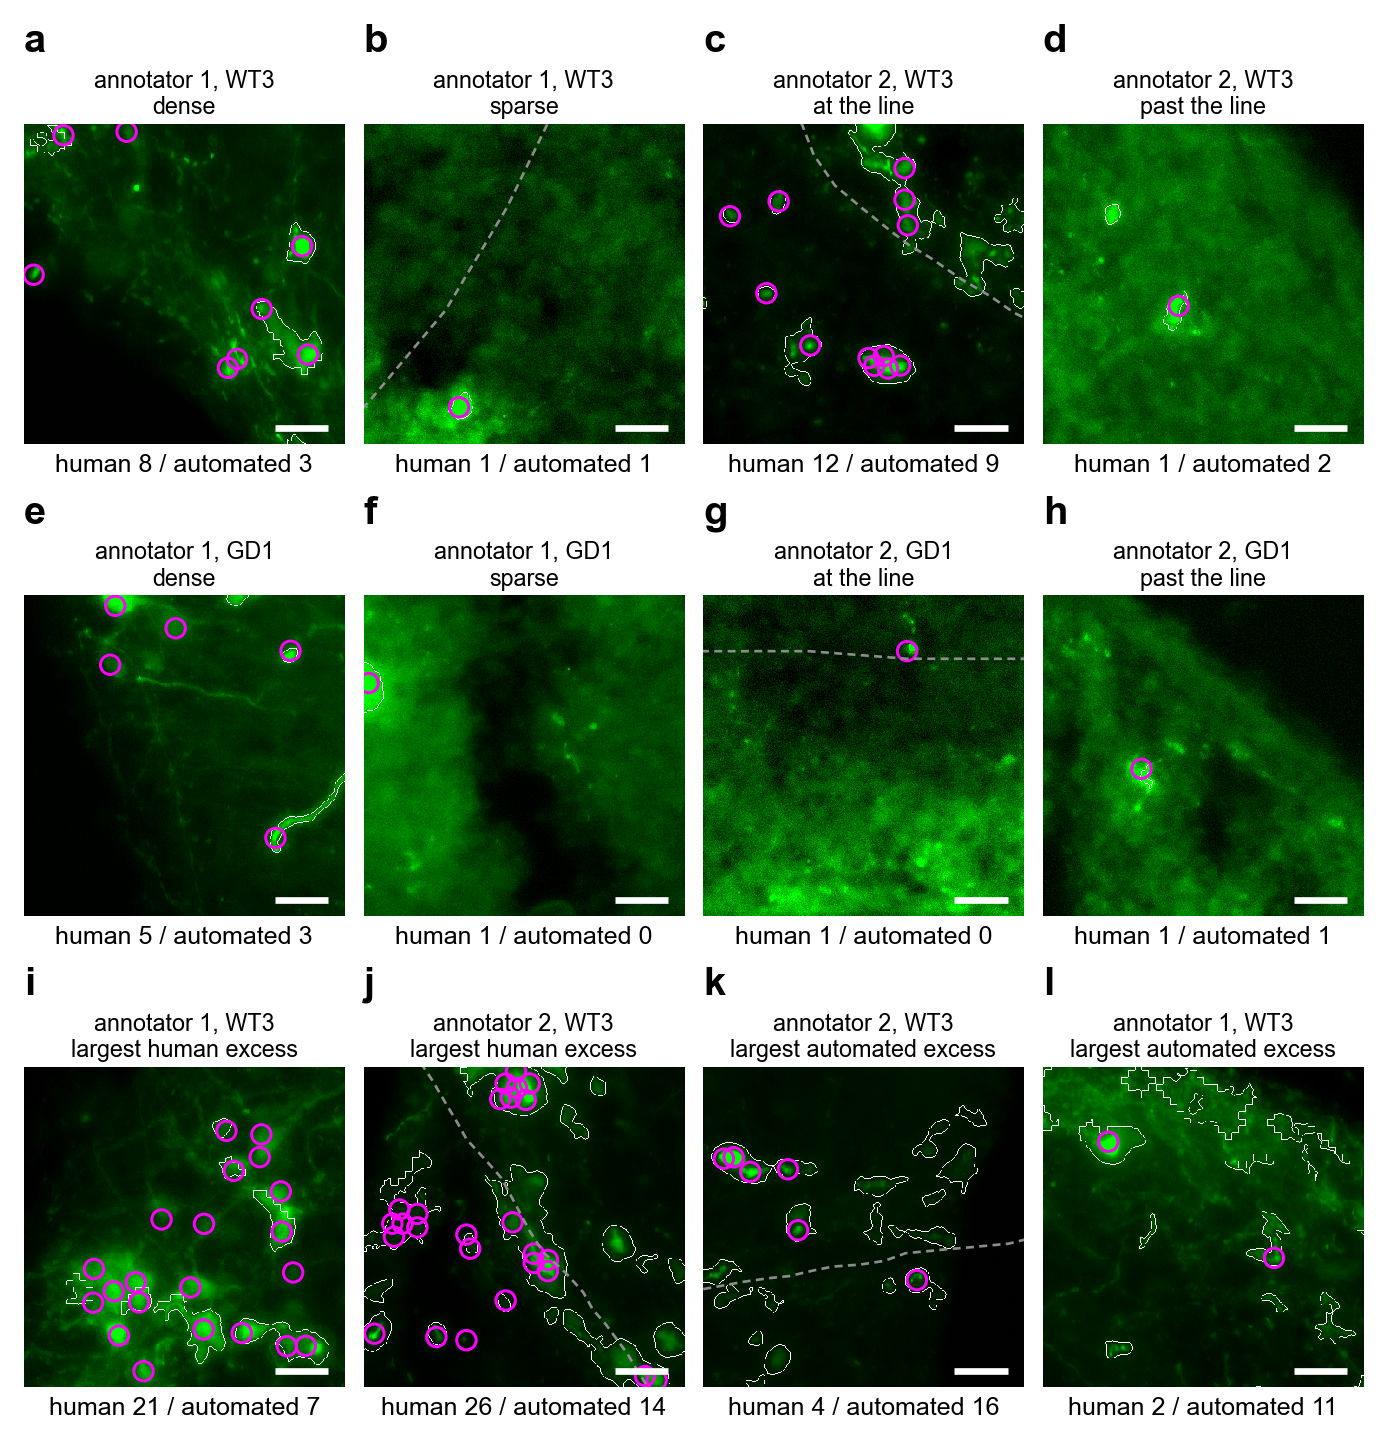

,region,display black (P0.5),display green (P99.8)
0,annotator 1 · WT3 · dense,151.0,3367.0
1,annotator 1 · WT3 · sparse,209.0,636.0
2,annotator 2 · WT3 · at the line,265.0,2719.0
3,annotator 2 · WT3 · past the line,156.0,649.0
4,annotator 1 · GD1 · dense,146.0,1820.0
5,annotator 1 · GD1 · sparse,161.0,1089.0
6,annotator 2 · GD1 · at the line,288.0,657.0
7,annotator 2 · GD1 · past the line,146.0,545.0
8,annotator 1 · WT3 · largest human excess,228.0,3454.0
9,annotator 2 · WT3 · largest human excess,181.0,6772.0


In [12]:
def outline_rgba(labels, keep):
    """White outlines of the counted objects, grey outlines of those outside the counted area."""
    rgba = np.zeros((*labels.shape, 4), np.float32)
    edges = find_boundaries(labels, mode="inner")
    counted_edge = edges & np.isin(labels, keep)
    rgba[counted_edge] = (1, 1, 1, 1)
    rgba[edges & ~counted_edge] = (*mpl.colors.to_rgb(MID), 1)
    return rgba


def draw_roi(ax, index, roi):
    r = RESULTS[index]
    voxel, (top, left) = r["voxel"], r["corner_um"]
    image = r["image"]
    lo, hi = np.percentile(image, DISPLAY_PCT)
    extent = (0, image.shape[1] * voxel, image.shape[0] * voxel, 0)      # µm from the square's corner
    ax.imshow(image, cmap=GREEN, vmin=lo, vmax=hi, extent=extent, interpolation="nearest")
    # which recomputed objects lie in the counted area (annotator 2: from 50 µm before the line to the far edge of the other organoid)
    s = counted[(counted["annotator"] == roi["annotator"]) & (counted["name"] == roi["name"])].iloc[0]
    ids = np.unique(r["labels"][r["labels"] > 0])
    centres = np.array([np.mean(np.nonzero(r["labels"] == i), axis=1) for i in ids]).reshape(-1, 2) * voxel
    centres += (top, left)
    if roi["annotator"] == "human annotator 2" and len(ids):
        away = away_of(pd.DataFrame(centres, columns=["y", "x"]), roi["name"], s["sign"])
        keep = ids[away >= AREA_2_UM]
    else:
        keep = ids
    ax.imshow(outline_rgba(r["labels"], keep), extent=extent, interpolation="nearest")
    # the human dots
    d = dots[(dots["annotator"] == roi["annotator"]) & (dots["name"] == roi["name"])][["y", "x"]].to_numpy()
    d = d[inside(d, roi)]
    ax.scatter(d[:, 1] - left, d[:, 0] - top, s=34, facecolor="none", edgecolor=MAGENTA, linewidth=0.9)
    # the junction line, where it crosses the square
    line = junction_line(roi["name"]) - (top, left)
    ax.plot(line[:, 1], line[:, 0], color=MID, lw=0.8, ls=(0, (3, 2)))
    # 20 µm scale bar
    side = image.shape[0] * voxel
    ax.plot([side - 6 - 20, side - 6], [side - 6, side - 6], color="white", lw=2, solid_capstyle="butt")
    ax.set(xlim=(0, side), ylim=(side, 0), xticks=[], yticks=[])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(roi["stratum"].replace(" · ", ", ", 1).replace(" · ", "\n", 1), fontsize=7, pad=3)
    ax.text(0.5, -0.03, f"human {int(roi['human'])} / automated {int(roi['automated'])}", transform=ax.transAxes,
            ha="center", va="top", fontsize=7.5)
    return lo, hi


# Shown here at ROI_DPI so each 120 µm square is drawn at its full resolution (0.325 µm per pixel); the saved files are 600 dpi.
ROI_DPI = 240
fig, axes = plt.subplots(3, 4, figsize=(7.2, 6.9), dpi=ROI_DPI, gridspec_kw={"hspace": 0.42, "wspace": 0.06})
ranges = []
for ax, (index, roi) in zip(axes.flat, rois.iterrows()):
    ranges.append((roi["stratum"], *draw_roi(ax, index, roi)))
panel_letters(axes, x=0.0, y=1.2)
save(fig, "fig3_regions_by_eye")
plt.show()
display(pd.DataFrame(ranges, columns=["region", f"display black (P{DISPLAY_PCT[0]:g})",
                                      f"display green (P{DISPLAY_PCT[1]:g})"]).round(0))

**Figure 3 | AF488⁺ cells counted by a human (magenta circles) and by the automated method (white outlines), in twelve 120 × 120 µm regions.** **a–h**, regions drawn at random (seed 3) from strata of the human-counted sections: annotator 1, dense and sparse; annotator 2, at the junction line and past it; WT3 and GD1. **i–l**, the regions with the largest difference between the two counts (two with a human excess, two with an automated excess). AF488 in green on black, display range per region from its 0.5th to 99.8th percentile. Grey outlines, objects outside the counted area (not counted); grey dashed line, junction line. Scale bar, 20 µm.

**What the regions show** (9 November 2026, mask at 8 SD; read with the table above: section codes as in section 1. The recomputed outlines matched 66 of the 67 stored objects in the twelve squares; in square k the crop gave 17 objects where 16 are stored, and one stored object was not found again within 1.5 µm.)

- **Where both agree (b, d, h).** A single bright cell body: one dot, one outline (d also outlines one compact spot without a dot).
- **Dim cells are missed, the main error at 8 SD (a, e, g, i).** In the dense WT3 square (a: 8 dots, 3 objects) the bright cells are outlined and the fainter dotted cells are not; in the dense GD1 square (e: 5 dots, 3 objects) two faint dotted cells have no outline, and one outline is a long labelled process with a dot at its end. In the GD1 square at the junction (g) the faint dotted cell stays below the threshold. In (i) (21 dots, 7 objects) most of the dotted cells are dim and only the brightest are outlined, several of them merged into one irregular object. In (f) the dotted cell is outlined, but the object's centroid lies just outside the square, so it counts 0 there.
- **Touching cells merged (c, j).** Five dots in one outline (c); a cluster of six dots in one outline at the top of (j) (26 dots, 14 objects), where dim cells left of the line are dotted without an outline.
- **Automated excess (k, l: WT3).** Irregular bright patches without dots: 16 in (k, section 2-03, 18 µm before the line, on both sides of it) and jagged outlines along a bright tissue edge plus small fragments in (l, 2 dots, 11 objects). The 8 SD threshold still counts bright background and process fragments where labelling is strong.
- **Brightness.** The GD1 squares near the junction are the dimmest: 99.8th percentile 657 (g) and 545 (h), against 636–6,772 in the WT3 squares.

**Overall.** At 8 SD the method still finds bright, compact cell bodies, but it misses many more dim cells than at 5 SD — in both genotypes, most in GD1 — while bright background patches and process fragments in strongly labelled WT3 regions are still counted. The errors no longer balance: the totals are about half the human totals, and the under-count is larger in GD1, which is the genotype-dependent bias of Figure 1b.


### Regions against human annotator 1 only

Annotator 1 counted every AF488⁺ cell of the whole section, so each of their squares can be read without the counted-area boundary. Twelve more 120 × 120 µm squares from annotator 1's 14 sections, none of them already in Figure 3, chosen the same way: eight drawn at random (seed 4), one per stratum and each from a different section where possible: for each genotype, *dense* (top 20 % of human + automated count), *sparse* (1–4 dots), *at the line* (centre −20 to 40 µm from it) and *past the line* (centre 120–240 µm past it); and the four squares with the largest excess of human over automated count and of automated over human (two each, from different sections). Drawn as Figure 3.

,stratum,section,away,human,automated
100,annotator 1 · WT3 · dense,1-05,-126.0,14,13
101,annotator 1 · WT3 · sparse,1-07,-351.0,1,1
102,annotator 1 · WT3 · at the line,1-06,-19.0,1,1
103,annotator 1 · WT3 · past the line,1-04,189.0,2,0
104,annotator 1 · GD1 · dense,1-14,-847.0,9,8
105,annotator 1 · GD1 · sparse,1-13,10.0,3,0
106,annotator 1 · GD1 · at the line,1-12,29.0,1,0
107,annotator 1 · GD1 · past the line,1-08,194.0,1,0
108,annotator 1 · WT3 · largest human excess,1-03,-844.0,24,13
109,annotator 1 · WT3 · largest human excess,1-05,-609.0,12,2


stored objects found again by the crop recomputation: 53 of 53


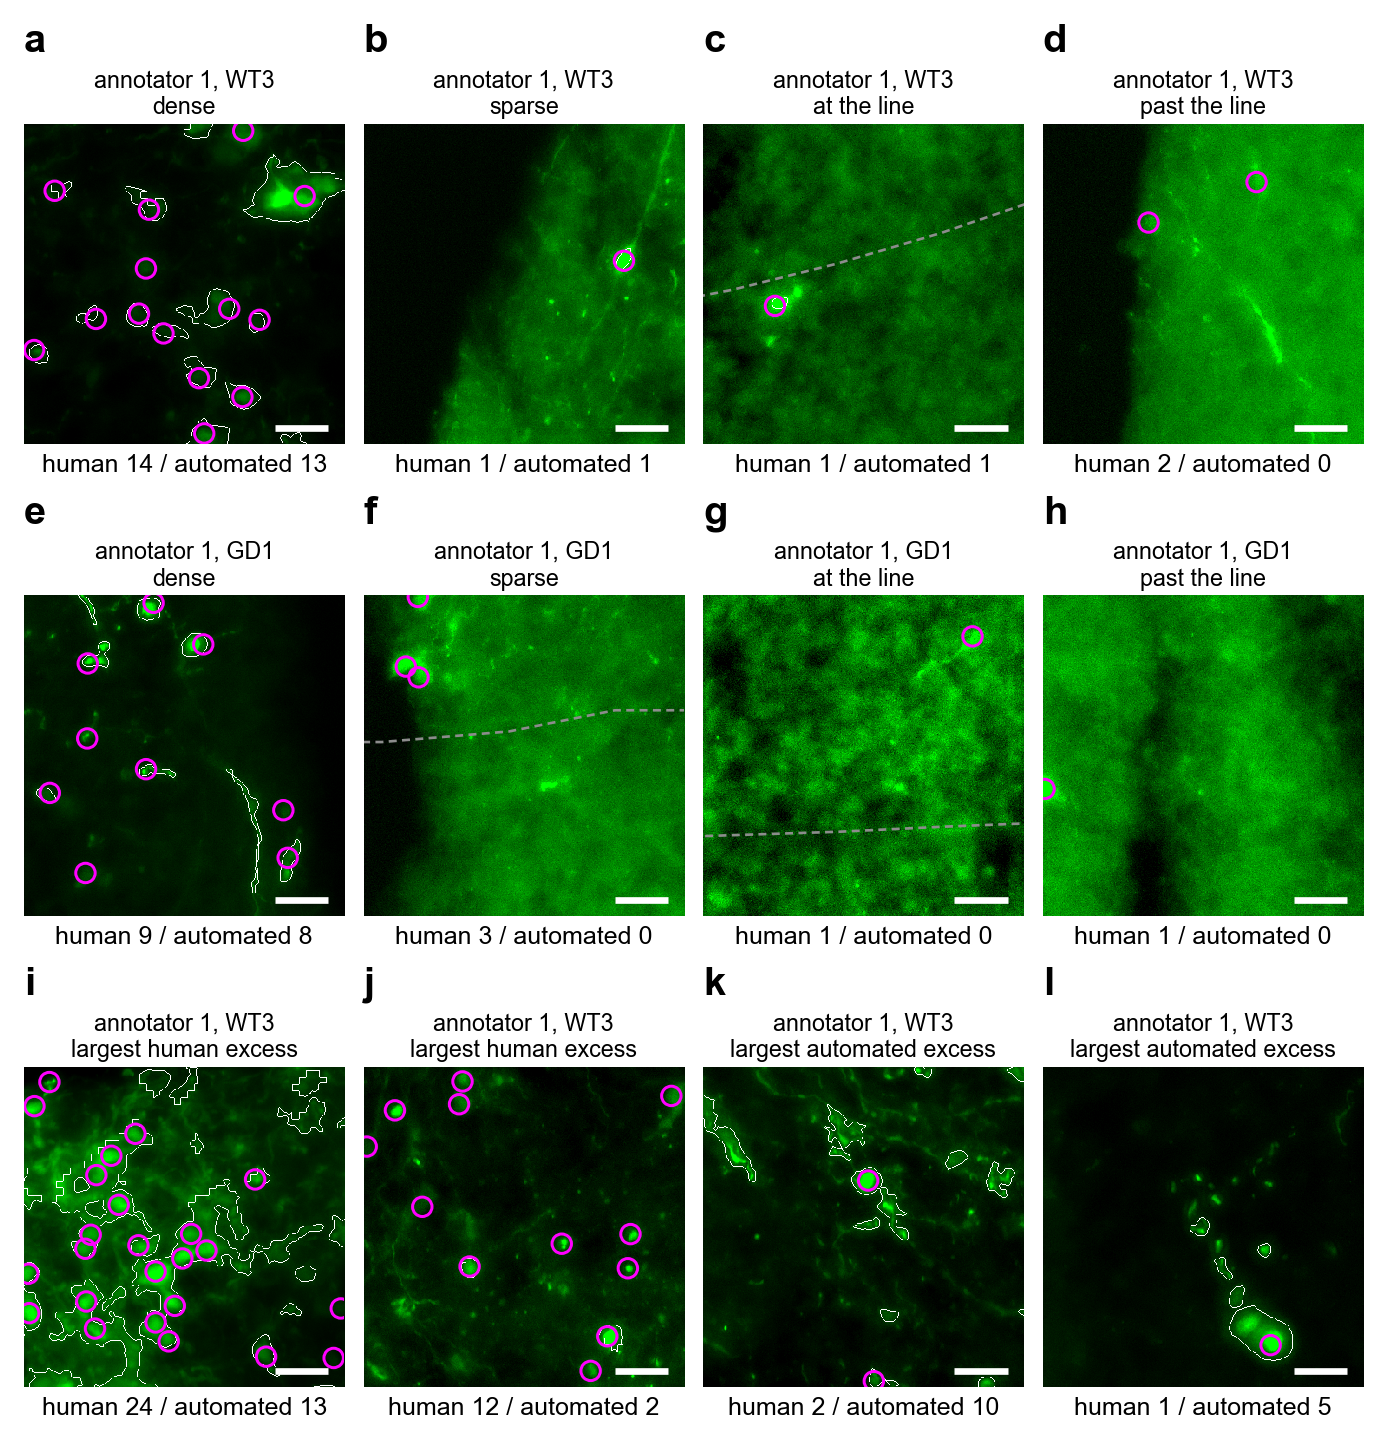

,region,display black (P0.5),display green (P99.8)
0,annotator 1 · WT3 · dense,417.0,6488.0
1,annotator 1 · WT3 · sparse,146.0,835.0
2,annotator 1 · WT3 · at the line,227.0,745.0
3,annotator 1 · WT3 · past the line,151.0,616.0
4,annotator 1 · GD1 · dense,154.0,2268.0
5,annotator 1 · GD1 · sparse,153.0,619.0
6,annotator 1 · GD1 · at the line,196.0,421.0
7,annotator 1 · GD1 · past the line,171.0,496.0
8,annotator 1 · WT3 · largest human excess,339.0,10551.0
9,annotator 1 · WT3 · largest human excess,442.0,2182.0


In [13]:
ROI_SEED_1 = 4
shown = set(zip(rois["name"], rois["cy"].round(1), rois["cx"].round(1)))          # the squares already in Figure 3
tiles_1 = tiles[(tiles["annotator"] == "human annotator 1")
                & ~pd.Series(list(zip(tiles["name"], tiles["cy"].round(1), tiles["cx"].round(1))), index=tiles.index).isin(shown)]
STRATA_1 = []
for g in GENOTYPES:
    STRATA_1 += [(f"annotator 1 · {g} · dense", lambda t, g=g: (t["Genotype"] == g) & (t["total"] >= dense_cut["human annotator 1"])),
                 (f"annotator 1 · {g} · sparse", lambda t, g=g: (t["Genotype"] == g) & t["human"].between(1, 4)),
                 (f"annotator 1 · {g} · at the line", lambda t, g=g: (t["Genotype"] == g) & t["away"].between(-20, 40) & (t["human"] >= 1)),
                 (f"annotator 1 · {g} · past the line", lambda t, g=g: (t["Genotype"] == g) & t["away"].between(120, 240) & (t["human"] >= 1))]
rng_1 = np.random.default_rng(ROI_SEED_1)
chosen_1, used_1 = [], set()
for stratum, test in STRATA_1:
    pool = tiles_1[test(tiles_1)]
    fresh = pool[~pool["name"].isin(used_1)]
    pool = fresh if len(fresh) else pool
    if not len(pool):
        print("no square for", stratum)
        continue
    pick = pool.iloc[int(rng_1.integers(len(pool)))]
    chosen_1.append(pick.to_dict() | {"stratum": stratum})
    used_1.add(pick["name"])
for direction, what in ((-1, "largest human excess"), (1, "largest automated excess")):
    order = tiles_1.assign(key=tiles_1["difference"] * direction).sort_values("key", ascending=False)
    order = order[order["key"] > 0].drop_duplicates("name")
    for _, pick in order.head(2).iterrows():
        chosen_1.append(pick.to_dict() | {"stratum": f"annotator 1 · {pick['Genotype']} · {what}"})
rois_1 = pd.DataFrame(chosen_1)
rois_1.index = range(100, 100 + len(rois_1))           # their own keys in RESULTS, beside Figure 3's
rois_1["section"] = [totals.set_index(["annotator", "name"]).at[(a, n), "section"] for a, n in zip(rois_1["annotator"], rois_1["name"])]
display(rois_1[["stratum", "section", "away", "human", "automated"]].round(0))

for name, group in rois_1.groupby("name", sort=False):
    RESULTS.update(zip(group.index, roi_masks(name, group[["cy", "cx"]].to_numpy())))
found_1, stored_1 = 0, 0        # the recomputed objects are the stored ones (centroids within 1.5 µm), as for Figure 3
for index, roi in rois_1.iterrows():
    stored = mask_objects(roi["name"])[["y", "x"]].to_numpy(float)
    mine = RESULTS[index]["centroids_um"]
    stored, mine = stored[inside(stored, roi)], mine[inside(mine, roi)]
    near_mine = cKDTree(mine).query(stored)[0] if len(mine) else np.full(len(stored), np.inf)
    found_1, stored_1 = found_1 + int((near_mine <= 1.5).sum()), stored_1 + len(stored)
print(f"stored objects found again by the crop recomputation: {found_1} of {stored_1}")

fig, axes = plt.subplots(3, 4, figsize=(7.2, 6.9), dpi=ROI_DPI, gridspec_kw={"hspace": 0.42, "wspace": 0.06})
ranges_1 = []
for ax, (index, roi) in zip(axes.flat, rois_1.iterrows()):
    ranges_1.append((roi["stratum"], *draw_roi(ax, index, roi)))
for ax in list(axes.flat)[len(rois_1):]:
    ax.axis("off")
panel_letters(axes, x=0.0, y=1.2)
save(fig, "fig3b_regions_annotator1")
plt.show()
display(pd.DataFrame(ranges_1, columns=["region", f"display black (P{DISPLAY_PCT[0]:g})",
                                        f"display green (P{DISPLAY_PCT[1]:g})"]).round(0))

**Figure 3b | AF488⁺ cells counted by human annotator 1 (magenta circles) and by the automated method (white outlines), in twelve further 120 × 120 µm regions.** **a–h**, regions drawn at random (seed 4) from annotator 1's sections, one per stratum: dense, sparse, at the junction line and past it; WT3 (a–d) and GD1 (e–h). **i–l**, the regions with the largest difference between the two counts in annotator 1's sections (two with a human excess, two with an automated excess; all four in WT3). Drawn as Figure 3: AF488 in green on black, display range per region from its 0.5th to 99.8th percentile; grey dashed line, junction line. Scale bar, 20 µm. None of these squares is in Figure 3; the recomputed outlines matched all 53 stored objects in them.

**What the regions show** (9 November 2026, mask at 8 SD).

- **Bright cells agree (a, b, c).** In the dense WT3 square (a: 14 dots, 13 objects) almost every dot lies in its own outline; (b) and (c) are one labelled cell, one dot, one outline.
- **Dim cells are missed, most of all in GD1 (d, f, g, h).** Annotator 1 dotted cells that stay below the section's threshold: two faint cells in the WT3 square past the line (d: 2 dots, 0 objects), and every dotted cell in the GD1 squares that are sparse (f: 3 dots, 0), at the line (g: 1, 0) and past it (h: 1, 0). These GD1 squares are among the dimmest of the twelve (99.8th percentile 619, 421 and 496, against 616–10,551 in the WT3 squares).
- **Mostly right in the dense GD1 square (e: 9 dots, 8 objects).** Most dotted cells are outlined, but three faint ones are not, and a long labelled process and small fragments are outlined without a dot, so the two errors nearly cancel.
- **Dense groups and small cells are under-counted (i, j).** In (i) (24 dots, 13 objects) large, jagged outlines join several dotted cells; in (j) (12 dots, 2 objects) most dotted cells are small, compact spots below the threshold.
- **Processes and fragments add objects (k, l).** Labelled processes and pieces of them are outlined without a dot (k: 10 objects against 2 dots); in (l) one bright cell is outlined together with fragments of its processes as separate objects (5 objects, 1 dot).

**Overall.** Against annotator 1 alone the picture is the same as in Figure 3: bright cell bodies are found, dim and small cells are missed (in every GD1 square but the dense one), and processes and fragments still add objects in WT3.


## Conclusion (9 November 2026, numbers of 10 November without the objects outside the section; counting method at median + 8 robust SD)

- **The automated count is about half the human count.** Counting AF488⁺ cells as objects of the AF488 mask at median + 8 robust SD gives section totals that rank like the human totals (Spearman ρ 0.90) but are about half of them (automated ÷ human 0.48×, 95 % CI 0.37–0.61; 27 sections). Lin's CCC is 0.66 (0.55–0.75), and single sections differ from an eighth to nearly twice the human count (95 % limits of agreement 0.12–1.83×). Against whole-section counts (annotator 1) CCC is 0.59, bias 0.54×, LoA 0.26–1.09×; near the junction (annotator 2) CCC is 0.34. Sections with few cells lose relatively more of them (Bland–Altman slope +0.42, P < 0.001).
- **Agreement is worse than with the 5 SD threshold.** The same mask at median + 5 robust SD, the counting method until 9 November 2026, had no overall bias (1.05×) and a CCC of 0.83 (0.87 against annotator 1). At 8 SD the mask under-counts much as the fine-tuned Cellpose does (0.44×). The change of threshold is not supported by the agreement with the human counts.
- **The error depends on genotype, more strongly.** The automated method finds 0.65× the human count in WT3 and 0.32× in GD1 (P = 0.003; at 5 SD 1.26× against 0.84×, P = 0.057). The regions show why: at 8 SD dim cells are missed, most of all in GD1, while bright background and process fragments are still counted in strongly labelled WT3 regions.
- **The conclusion holds in direction.** On the human-counted sections, human and automated counts agree that WT3 has more AF488⁺ cells per mm of junction than GD1 (human 1.46× and 1.58×; automated 2.01× and 7.09×). On all 614 sections the automated method gives 3.05× (1.96–4.76, P < 0.001) for crossed AF488⁺ cells (anywhere on the far side of the junction line), against 2.28× (1.42–3.67) at 5 SD.
- **The fold is overestimated, more than at 5 SD.** Because of the stronger genotype-dependent bias, the automated fold should be reported as likely to overestimate the true difference. The paper can claim that WT3 has more crossed AF488⁺ cells than GD1, not the size of the fold; the human folds on the same sections (1.46–1.58×) and the 5 SD fold (2.28×) should be reported beside the 8 SD fold.

## Methods

*Validation of the automated count.* Two investigators counted AF488⁺ cells by hand by placing one point on each labelled cell on the AF488 image (maximum over z). Human annotator 1 counted whole sections (14 sections: 7 WT3, 7 GD1; 11 slides; 3,377 cells). Human annotator 2 counted from 50 µm before the junction line across the whole unlabelled organoid (13 sections: 8 WT3, 5 GD1; 11 slides; 730 cells in that area). The side of each point was taken from the junction line extended straight past both ends; AF488's home side was the side holding more AF488 mask-object area. Automated counts were taken in the same area of the same sections. For each section the agreement of the totals was summarised by Lin's concordance correlation coefficient on log₁₀ counts and by Bland–Altman analysis of log₂(automated ÷ human) (bias and 95 % limits of agreement, back-transformed to ratios), with 95 % confidence intervals from 2,000 bootstrap resamples of sections (stratified by annotator when pooled); proportional bias was tested by regressing the log ratio on the log geometric mean of the two counts. Genotypes were compared on the human-counted sections by the two-sided Mann–Whitney test on counts per mm of junction line. Across all 614 analysed sections, AF488⁺ objects lying on the far side of the junction line (crossed), per mm of junction line, were compared between genotypes with a linear mixed model on log(1 + y), with genotype and experiment as fixed effects and slide as a random effect (statsmodels, REML). The fold change is the exponentiated genotype coefficient with its Wald 95 % CI. *Automated count.* The AF488 image (maximum over z) was smoothed with a Gaussian (σ 0.5 µm), its local background (Gaussian, σ 20 µm) was subtracted, and the result was thresholded at the median + 8 robust SD (1.4826 × median absolute deviation) of the section's own tissue pixels, one threshold per section. The tissue mask came from Otsu thresholding of the nuclear stain. Objects smaller than 20 µm² were removed and holes smaller than 10 µm² filled. Each connected object was counted as one cell, with its position given by its centroid. The same mask at the median + 5 robust SD is reported for comparison.
